# 实验2：配置 VS Code 与 Jupyter

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

掌握虚拟环境、Notebook 内核、单元格执行顺序，以及可移植的图片路径。

## 实验原理

本实验使用 VS Code 编写并运行 Jupyter Notebook。虚拟环境保存本项目使用的 Python 包，Notebook 内核负责执行单元格中的代码。安装依赖时使用的 Python 与 Notebook 内核应属于同一个环境。Notebook 变量在同一内核中保留，执行顺序会影响结果。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab02"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 检查当前内核与素材

运行此单元格，确认不是系统 Python；项目可以移动位置，不需要写死电脑上的绝对路径。


In [2]:
print("当前内核:", sys.executable)
print("lab 根目录:", ROOT)
for path in sorted((ASSETS / "pdf").glob("*.png")):
    print(path.relative_to(ROOT))
assert (ASSETS / "pdf/bottle_cap.png").is_file()


当前内核: /private/tmp/opencv_lab_verify/bin/python
lab 根目录: /Users/yiqing/Documents/ChatGPT/机器学习授课/lab
assets/pdf/bottle_cap.png
assets/pdf/circuit_board.png
assets/pdf/coins.png
assets/pdf/mechanical_part.png


## 3. 路径、数组与 Notebook 输出

在 Notebook 中用 Matplotlib 展示图片，图片输出保留在单元格下方，无需独立 GUI 窗口。


宽 370，高 370，通道数 3
左上角 BGR 像素: [192, 241, 249]


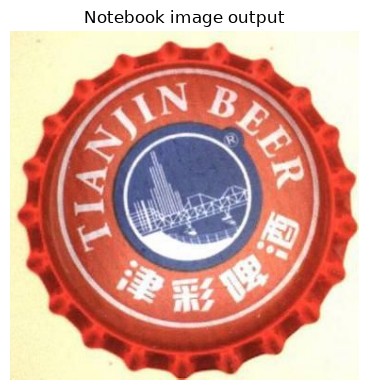

In [3]:
relative_path = Path("pdf/bottle_cap.png")
image_path = ASSETS / relative_path
cap = read_image(image_path)
height, width, channels = cap.shape
print(f"宽 {width}，高 {height}，通道数 {channels}")
print("左上角 BGR 像素:", cap[0, 0].tolist())
show_images({"Notebook image output": cap}, cols=1)


## 4. 单元格执行与独立实验

改变 scale 后重复运行；如果重启内核，要先重新运行准备环境单元格。每个实验均可独立从头执行。


缩放后: (185, 185, 3)


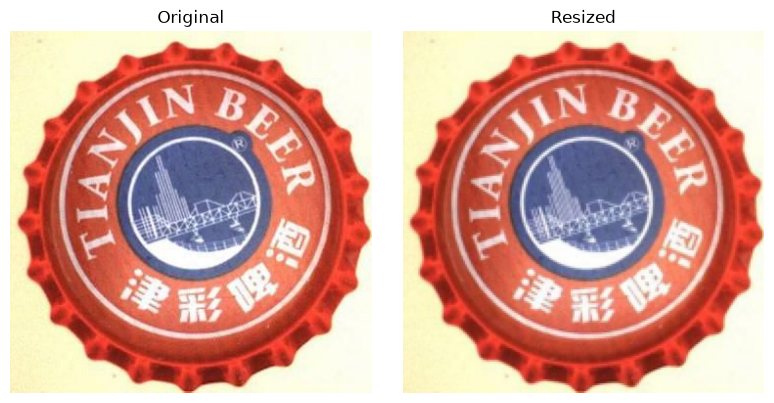

In [4]:
scale = 0.5  # 练习：改为 0.25 或 0.75
small = cv2.resize(cap, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
save_image(OUT / "resized_cap.png", small)
print("缩放后:", small.shape)
show_images({"Original": cap, "Resized": small}, cols=2)


## 记录与思考

1. 重启内核后只运行最后一个单元格，会出现什么问题？
2. `Path.cwd()` 与图片所在目录有什么区别？
3. 用“重启内核并全部运行”确认实验可复现。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab02/`；运行本 Notebook 不会改写原始素材。
